In [87]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression


In [88]:
RawData = np.transpose(np.asarray(np.genfromtxt('Trabucchi_data_combined.csv',delimiter=',',skip_header=1)))
# 0 = logM
logMIndex = 0
# 1 = logL
logLIndex = 1
# 2 = logR
logRIndex = 2
# 3 = logP0 from Trabucchi model
logP0Index = 3
# 4 = logP1 from COLIBRI model
logP1Index=4
# 5 = log(C/O)
logCORatioIndex=5

In [89]:
RawData[5]

array([-0.5761  , -0.57597 , -0.57584 , ...,  0.064131,  0.064423,
        0.064715])

In [90]:
def PulsationModeSort (input_array):
    # DON'T TRUST THIS SORT METHOD. MODES IN DATA SET ARE UNRELIABLE
    FundamentalPulsators = []
    OvertonePulsators = []
    i = 0
    while i < len(input_array[ModeIndex]):
        if input_array[ModeIndex][i] == 0:
            FundamentalPulsators.append(i)
        if input_array[ModeIndex][i] == 1:
            OvertonePulsators.append(i)
        i += 1
    FundamentalModeStars = np.transpose(input_array.transpose()[FundamentalPulsators])
    FirstOvertoneModeStars = np.transpose(input_array.transpose()[OvertonePulsators])
    return FundamentalModeStars, FirstOvertoneModeStars

def CompositionSort (input_array):
    ORichStarsIndices = []
    CRichStarsIndices = []
    i = 0
    while i < len(input_array[logCORatioIndex]):
        if input_array[logCORatioIndex][i] < 0:
            ORichStarsIndices.append(i)
        if input_array[logCORatioIndex][i] > 0:
            CRichStarsIndices.append(i)
        i += 1
    ORichStars = np.transpose(input_array.transpose()[ORichStarsIndices])
    CRichStars = np.transpose(input_array.transpose()[CRichStarsIndices])
    return ORichStars, CRichStars

In [91]:
def MassSort (input_array):
    logMLT005 = []
    logMGT005 = []
    i = 0
    while i < len(input_array[logMIndex]):
        if input_array[logMIndex][i] <= 0.05: # For all stars with logM < 0.05
            logMLT005.append(i)
        if input_array[logMIndex][i] > -0.05 and input_array[logMIndex][i] <= 0.4 : # For all stars with logM > -0.05 - yes, there needs to be overlap!
            logMGT005.append(i)
        #if input_array[logMIndex][i] > 0.4:
            #print("Star", i, "of mass",10**(input_array[6][i]),"cut")
        i += 1
    #LowMassStars = np.transpose(input_array.transpose()[logMLT005])
    #HighMassStars = np.transpose(input_array.transpose()[logMGT005])
    return logMLT005, logMGT005

def MassFilter (Mass_Data):
    logMListArray = []
    i = 0
    while i<len(Mass_Data):
        if Mass_Data[i] < 0.4:
            logMListArray.append(i)
        i += 1
    return logMListArray

In [92]:
#P0Stars, P1Stars = PulsationModeSort(DataToFit)
ORichStars, CRichStars = CompositionSort(RawData)
DataToFit = ORichStars
LowLogMToFitStars, HighLogMToFitStars = MassSort(DataToFit)
logMData = DataToFit[logMIndex]
logMLT005Data = DataToFit[logMIndex][LowLogMToFitStars]
logMMGT005Data = DataToFit[logMIndex][HighLogMToFitStars]
logRData = DataToFit[logRIndex]
logRMLT005Data = DataToFit[logRIndex][LowLogMToFitStars]
logRMGT005Data = DataToFit[logRIndex][HighLogMToFitStars]
logLData = DataToFit[logLIndex]
logLLT005Data = DataToFit[logLIndex][LowLogMToFitStars]
logLMGT005Data = DataToFit[logLIndex][HighLogMToFitStars]
logPData = DataToFit[logP0Index]
logP1Data = DataToFit[logP1Index]

In [93]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMData
x1 = logRData
y = logP1Data

data = pandas.DataFrame({'logM': x0, 'logR': x1, 'logP': y})

# Fit the model
model = ols("logP ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 3.751e+10
Date:                Sun, 08 Nov 2020   Prob (F-statistic):               0.00
Time:                        18:48:18   Log-Likelihood:                 10196.
No. Observations:                1126   AIC:                        -2.039e+04
Df Residuals:                    1123   BIC:                        -2.037e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.5543   1.32e-05  -1.18e+05      0.0

M: logP = -1.55428(1) - 0.528686(6)logM + 1.570244(6)logR

In [94]:
M1_PMR = model._results.params
M1_PMR_Int, M1_PMR_M, M1_PMR_R = M1_PMR[0], M1_PMR[1], M1_PMR[2]

In [95]:
logPData

array([1.8722, 1.8099, 1.8969, ..., 2.1417, 3.006 , 2.9487])

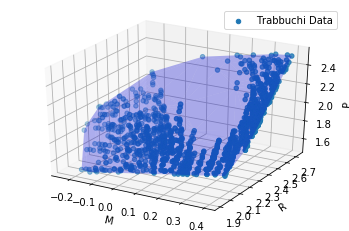

In [96]:
xs = logMData
ys = logRData
zs = logP1Data
zs_fit = M1_PMR_Int + M1_PMR_M*logMData + M1_PMR_R*logRData


fig = plt.figure()
ax = fig.gca(projection='3d')
ax.scatter(xs, ys, zs, label='Trabbuchi Data')
ax.plot_trisurf(xs,ys,zs_fit,color='blue',alpha=0.3)
ax.legend()
ax.set_xlabel('M    ')
ax.set_ylabel('R    ')
ax.set_zlabel('P    ')

plt.show()

In [97]:
Z

array([[-0.00982064, -0.00989454, -0.00996894, ..., -0.01004383,
        -0.00996894, -0.00989454],
       [-0.00989454, -0.009969  , -0.01004395, ..., -0.01011941,
        -0.01004395, -0.009969  ],
       [-0.00996894, -0.01004395, -0.01011947, ..., -0.01019549,
        -0.01011947, -0.01004395],
       ...,
       [-0.00896432, -0.0090351 , -0.00910636, ...,  0.00536775,
         0.00540973,  0.00545124],
       [-0.00891074, -0.00898105, -0.00905183, ...,  0.00513561,
         0.00517771,  0.00521933],
       [-0.00885726, -0.0089271 , -0.00899742, ...,  0.00490868,
         0.00495088,  0.00499262]])

In [98]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMData
x1 = logRData
y = logPData

data = pandas.DataFrame({'logM': x0, 'logR': x1, 'logP': y})

# Fit the model
model = ols("logP ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 4.744e+05
Date:                Sun, 08 Nov 2020   Prob (F-statistic):               0.00
Time:                        18:48:19   Log-Likelihood:                 3580.0
No. Observations:                1126   AIC:                            -7154.
Df Residuals:                    1123   BIC:                            -7139.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.2342      0.005   -476.673      0.0

M: logP = -2.234(5) - 0.780(2)logM + 2.027(2)logR

In [99]:
M0_PMR = model._results.params
M0_PMR_Int, M0_PMR_M, M0_PMR_R = M0_PMR[0], M0_PMR[1], M0_PMR[2]

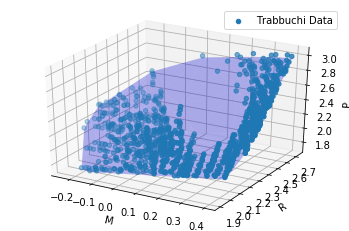

In [100]:
xs = logMData
ys = logRData
zs = logPData
zs_fit = M0_PMR_Int + M0_PMR_M*logMData + M0_PMR_R*logRData


fig = plt.figure()
ax = fig.gca(projection='3d')
ax.scatter(xs, ys, zs, label='Trabbuchi Data')
ax.plot_trisurf(xs,ys,zs_fit,color='blue',alpha=0.3)
ax.legend()
ax.set_xlabel('M    ')
ax.set_ylabel('R    ')
ax.set_zlabel('P    ')

plt.show()

In [101]:
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLMGT005Data
x1 = logMMGT005Data
y = logRMGT005Data

data = pandas.DataFrame({'logL': x0, 'logM': x1, 'logR': y})

# Fit the model
model = ols("logR ~ logL + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logR   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                 1.216e+05
Date:                Sun, 08 Nov 2020   Prob (F-statistic):               0.00
Time:                        18:48:19   Log-Likelihood:                 2921.5
No. Observations:                 950   AIC:                            -5837.
Df Residuals:                     947   BIC:                            -5823.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2634      0.006    -41.550      0.0

M Stars, logM>0: logR = -0.263(6) + 0.6983(2)logL - 0.285(4)logM

In [102]:
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLLT005Data
x1 = logMLT005Data
x2 = logMLT005Data**2
y = logRMLT005Data

data = pandas.DataFrame({'logL': x0, 'logM': x1, 'logMSq':x2, 'logR': y})

# Fit the model
model = ols("logR ~ logL + logM + logMSq", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logR   R-squared:                       0.948
Model:                            OLS   Adj. R-squared:                  0.947
Method:                 Least Squares   F-statistic:                     2134.
Date:                Sun, 08 Nov 2020   Prob (F-statistic):          2.26e-225
Time:                        18:48:19   Log-Likelihood:                 822.26
No. Observations:                 356   AIC:                            -1637.
Df Residuals:                     352   BIC:                            -1621.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3234      0.031    -10.443      0.0

M Stars, logM<0: logR = -0.323(31) + 0.716(9)logL - 0.305(41)logM - 1.096(245)(logM)^2

In [103]:
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logMData
y = logRData

data = pandas.DataFrame({'logL': x0, 'logM': x1, 'logR': y})

# Fit the model
model = ols("logR ~ logL + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logR   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.990
Method:                 Least Squares   F-statistic:                 5.800e+04
Date:                Sun, 08 Nov 2020   Prob (F-statistic):               0.00
Time:                        18:48:19   Log-Likelihood:                 2965.3
No. Observations:                1126   AIC:                            -5925.
Df Residuals:                    1123   BIC:                            -5910.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2409      0.009    -26.581      0.0

M Stars, no Msplit: logR = -0.241(9) + 0.690(3)logL - 0.251(4)logM

In [105]:
M0_RLM = model._results.params
M0_RLM_Int, M0_RLM_L, M0_RLM_M = M0_RLM[0], M0_RLM[1], M0_RLM[2]

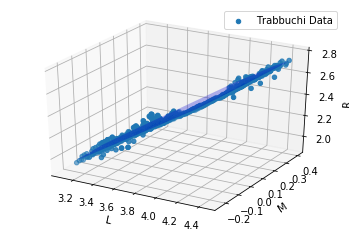

In [106]:
xs = logLData
ys = logMData
zs = logRData
zs_fit = M0_RLM_Int + M0_RLM_L*logLData + M0_RLM_M*logMData


fig = plt.figure()
ax = fig.gca(projection='3d')
ax.scatter(xs, ys, zs, label='Trabbuchi Data')
ax.plot_trisurf(xs,ys,zs_fit,color='blue',alpha=0.3)
ax.legend()
ax.set_xlabel('L    ')
ax.set_ylabel('M    ')
ax.set_zlabel('R    ')

plt.show()

In [12]:
#P0Stars, P1Stars = PulsationModeSort(DataToFit)
DataToFit = CRichStars
LowLogMToFitStars, HighLogMToFitStars = MassSort(DataToFit)
logMData = DataToFit[logMIndex]
logMLT005Data = DataToFit[logMIndex][LowLogMToFitStars]
logMMGT005Data = DataToFit[logMIndex][HighLogMToFitStars]
logRData = DataToFit[logRIndex]
logRMLT005Data = DataToFit[logRIndex][LowLogMToFitStars]
logRMGT005Data = DataToFit[logRIndex][HighLogMToFitStars]
logLData = DataToFit[logLIndex]
logLLT005Data = DataToFit[logLIndex][LowLogMToFitStars]
logLMGT005Data = DataToFit[logLIndex][HighLogMToFitStars]
logPData = DataToFit[logP0Index]
logP1Data = DataToFit[logP1Index]

In [13]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMData
x1 = logRData
y = logP1Data

data = pandas.DataFrame({'logM': x0, 'logR': x1, 'logP': y})

# Fit the model
model = ols("logP ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 4.641e+10
Date:                Wed, 06 May 2020   Prob (F-statistic):               0.00
Time:                        23:41:48   Log-Likelihood:                 9681.8
No. Observations:                1073   AIC:                        -1.936e+04
Df Residuals:                    1070   BIC:                        -1.934e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.5543   1.32e-05  -1.17e+05      0.0

C Stars: logP1 = -1.55431(1) - 0.528676(8)logM + 1.570255(6)logR

In [14]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMData
x1 = logRData
y = logPData

data = pandas.DataFrame({'logM': x0, 'logR': x1, 'logP': y})

# Fit the model
model = ols("logP ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.737e+05
Date:                Wed, 06 May 2020   Prob (F-statistic):               0.00
Time:                        23:41:48   Log-Likelihood:                 2921.8
No. Observations:                1073   AIC:                            -5838.
Df Residuals:                    1070   BIC:                            -5823.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.2855      0.007   -317.064      0.0

C Stars: logP0 = -2.285(7) - 0.826(4)logM + 2.043(3)logR

In [15]:
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logMData
y = logRData

data = pandas.DataFrame({'logL': x0, 'logM': x1, 'logR': y})

# Fit the model
model = ols("logR ~ logL + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logR   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     5194.
Date:                Wed, 06 May 2020   Prob (F-statistic):               0.00
Time:                        23:41:48   Log-Likelihood:                 1691.0
No. Observations:                1073   AIC:                            -3376.
Df Residuals:                    1070   BIC:                            -3361.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3228      0.027    -11.943      0.0

C Stars: logR = -0.323(27) + 0.737(7)logL - 0.371(14)logM

In [16]:
#P0Stars, P1Stars = PulsationModeSort(DataToFit)
DataToFit = RawData
LowLogMToFitStars, HighLogMToFitStars = MassSort(DataToFit)
logMData = DataToFit[logMIndex]
logMLT005Data = DataToFit[logMIndex][LowLogMToFitStars]
logMMGT005Data = DataToFit[logMIndex][HighLogMToFitStars]
logRData = DataToFit[logRIndex]
logRMLT005Data = DataToFit[logRIndex][LowLogMToFitStars]
logRMGT005Data = DataToFit[logRIndex][HighLogMToFitStars]
logLData = DataToFit[logLIndex]
logLLT005Data = DataToFit[logLIndex][LowLogMToFitStars]
logLMGT005Data = DataToFit[logLIndex][HighLogMToFitStars]
logPData = DataToFit[logP0Index]
logP1Data = DataToFit[logP1Index]

In [17]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMData
x1 = logRData
y = logP1Data

data = pandas.DataFrame({'logM': x0, 'logR': x1, 'logP': y})

# Fit the model
model = ols("logP ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.400e+10
Date:                Wed, 06 May 2020   Prob (F-statistic):               0.00
Time:                        23:41:48   Log-Likelihood:                 19875.
No. Observations:                2199   AIC:                        -3.974e+04
Df Residuals:                    2196   BIC:                        -3.973e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.5543   8.17e-06   -1.9e+05      0.0

All Stars: logP1 = -1.554291(8) - 0.528686(4)logM + 1.570249(4)logR

In [18]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMData
x1 = logRData
y = logPData

data = pandas.DataFrame({'logM': x0, 'logR': x1, 'logP': y})

# Fit the model
model = ols("logP ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 4.546e+05
Date:                Wed, 06 May 2020   Prob (F-statistic):               0.00
Time:                        23:41:48   Log-Likelihood:                 5864.4
No. Observations:                2199   AIC:                        -1.172e+04
Df Residuals:                    2196   BIC:                        -1.171e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.2314      0.005   -466.754      0.0

All Stars: logP = -2.231(5) - 0.791(2)logM + 2.022(2)logR

In [19]:
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
x1 = logMData
y = logRData

data = pandas.DataFrame({'logL': x0, 'logM': x1, 'logR': y})

# Fit the model
model = ols("logR ~ logL + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                   logR   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.918
Method:                 Least Squares   F-statistic:                 1.223e+04
Date:                Wed, 06 May 2020   Prob (F-statistic):               0.00
Time:                        23:41:48   Log-Likelihood:                 3402.2
No. Observations:                2199   AIC:                            -6798.
Df Residuals:                    2196   BIC:                            -6781.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3863      0.018    -21.472      0.0

All Stars: logR = -0.386(18) + 0.743(5) logL - 0.332(9) logM